# Sección 3.3 Preparación de datos

## 1. Importaciones, parámetros y carga de la tabla unificada (salida de 3.2)

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from pathlib import Path
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')

DATA = Path.cwd() / 'data'
FIG = Path.cwd() / 'figuras_3_3'
FIG.mkdir(exist_ok=True)

# Parámetros de la preparación (se documentan en el informe)
UMBRAL_NULOS = 0.60                    # se eliminan variables con más de 60 % de nulos
UMBRAL_Z = 3                           # outlier si |z| >= 3
FECHA_REF = pd.Timestamp('1998-12-31') # último día con datos en la base Berka (trans.asc llega a 981231)

In [28]:
df_berka = pd.read_csv('df_berka_unificado.csv')
print('Dimensión de la tabla unificada:', df_berka.shape)
df_berka.info()

Dimensión de la tabla unificada: (4500, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   client_id            4500 non-null   int64  
 1   birth_number         4500 non-null   int64  
 2   district_id_client   4500 non-null   int64  
 3   disp_id              4500 non-null   int64  
 4   account_id           4500 non-null   int64  
 5   type                 4500 non-null   object 
 6   district_id_account  4500 non-null   int64  
 7   frequency            4500 non-null   object 
 8   date                 4500 non-null   int64  
 9   amount               682 non-null    float64
 10  duration             682 non-null    float64
 11  payments             682 non-null    float64
 12  status               682 non-null    object 
 13  target               682 non-null    float64
dtypes: float64(4), int64(7), object(3)
memory us

In [29]:
# Verificación de granularidad: 1 fila por cliente titular, sin duplicados
print('client_id único          :', df_berka['client_id'].is_unique)
print('Filas completamente repetidas:', df_berka.duplicated().sum())
print('Valores de type          :', df_berka['type'].unique())
df_berka.head()

client_id único          : True
Filas completamente repetidas: 0
Valores de type          : ['OWNER']


,client_id,birth_number,district_id_client,disp_id,account_id,type,district_id_account,frequency,date,amount,duration,payments,status,target
0,1,706213,18,1,1,OWNER,18,POPLATEK MESICNE,950324,NaN,NaN,NaN,NaN,NaN
1,2,450204,1,2,2,OWNER,1,POPLATEK MESICNE,930226,80952.0,24.0,3373.0,A,1.0
2,4,561201,5,4,3,OWNER,5,POPLATEK MESICNE,970707,NaN,NaN,NaN,NaN,NaN
3,6,190922,12,6,4,OWNER,12,POPLATEK MESICNE,960221,NaN,NaN,NaN,NaN,NaN
4,7,290125,15,7,5,OWNER,15,POPLATEK MESICNE,970530,NaN,NaN,NaN,NaN,NaN


## 2. Valores nulos y regla del 60 %

Primero se mide el porcentaje de nulos por variable. La regla de la sección 3.3 indica eliminar las variables
con **más del 60 %** de valores nulos. Antes de aplicarla se diagnostica *por qué* hay nulos.

In [30]:
nulos = pd.DataFrame({
    'n_nulos': df_berka.isna().sum(),
    'pct_nulos': (df_berka.isna().mean() * 100).round(2)
})
nulos['supera_60%'] = nulos['pct_nulos'] > UMBRAL_NULOS * 100
nulos.sort_values('pct_nulos', ascending=False)

,n_nulos,pct_nulos,supera_60%
status,3818,84.84,True
target,3818,84.84,True
duration,3818,84.84,True
payments,3818,84.84,True
amount,3818,84.84,True
client_id,0,0.00,False
type,0,0.00,False
account_id,0,0.00,False
disp_id,0,0.00,False
district_id_client,0,0.00,False


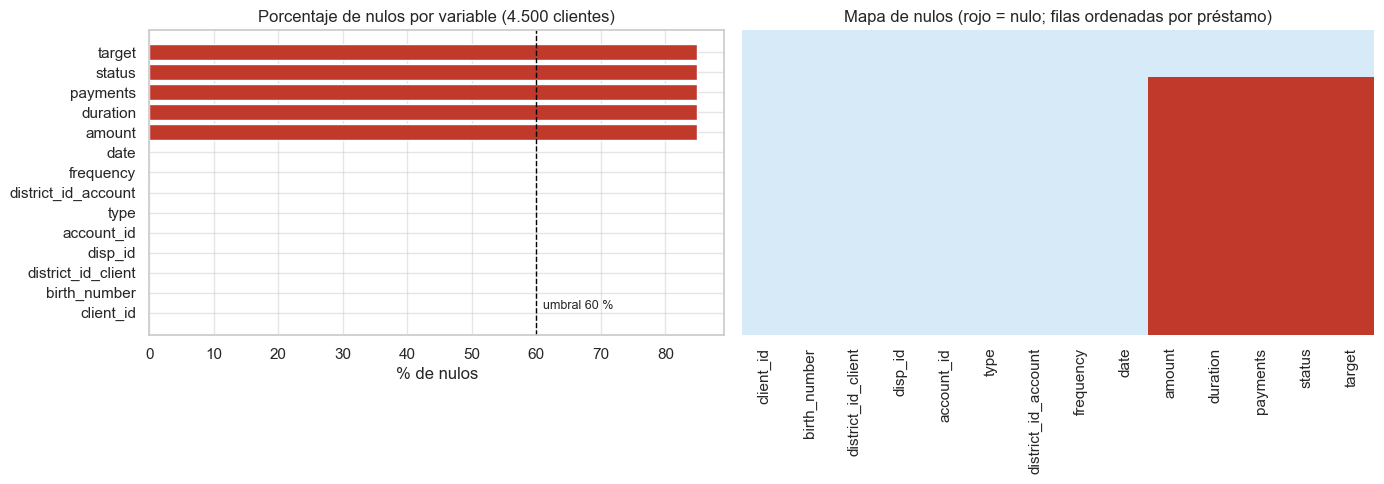

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 1.1]})

orden = nulos.sort_values('pct_nulos')
colores = ['#c0392b' if v else '#2e86c1' for v in orden['supera_60%']]
ax[0].barh(orden.index, orden['pct_nulos'], color=colores)
ax[0].axvline(UMBRAL_NULOS * 100, color='black', ls='--', lw=1)
ax[0].text(UMBRAL_NULOS * 100 + 1, 0.2, 'umbral 60 %', fontsize=9)
ax[0].set_xlabel('% de nulos')
ax[0].set_title('Porcentaje de nulos por variable (4.500 clientes)')

# Se ordena por presencia de préstamo para que el bloque estructural se vea claro
mapa = df_berka.sort_values('target', na_position='last').isnull()
sns.heatmap(mapa, cbar=False, yticklabels=False, ax=ax[1], cmap=sns.color_palette(['#d6eaf8', '#c0392b']))
ax[1].set_title('Mapa de nulos (rojo = nulo; filas ordenadas por préstamo)')
plt.tight_layout()
plt.savefig(FIG / '01_nulos.png', dpi=130, bbox_inches='tight')
plt.show()

### 2.1 Aplicación literal de la regla del 60 %

Se define una función reutilizable y se aplica **como diagnóstico** sobre la tabla completa (sin sobrescribirla).

In [32]:
def eliminar_por_nulos(df, umbral=UMBRAL_NULOS):
    """Elimina las columnas con proporción de nulos mayor al umbral. Devuelve (df, columnas_eliminadas)."""
    prop = df.isna().mean()
    cols = prop[prop > umbral].index.tolist()
    return df.drop(columns=cols), cols

_, cols_sobre_60 = eliminar_por_nulos(df_berka)
print('Variables con > 60 % de nulos en la tabla completa:', cols_sobre_60)

Variables con > 60 % de nulos en la tabla completa: ['amount', 'duration', 'payments', 'status', 'target']


### 2.2 Diagnóstico: ¿de dónde vienen esos nulos?

Las 5 variables marcadas pertenecen al bloque de **préstamo** (`loan.asc`, unido con `how='left'`).
Si los nulos coinciden en las mismas filas, no son datos perdidos sino **nulos estructurales**: el cliente simplemente no tiene préstamo.

In [33]:
cols_prestamo = ['amount', 'duration', 'payments', 'status', 'target']
mascara = df_berka[cols_prestamo].isna()

print('¿Las 5 columnas son nulas exactamente en las mismas filas?:', mascara.nunique(axis=1).eq(1).all())

tiene_prestamo = df_berka['target'].notna()
resumen = tiene_prestamo.value_counts().rename({True: 'con préstamo (etiquetados)', False: 'sin préstamo'})
print(resumen)
print(f"\nPorcentaje sin préstamo: {(~tiene_prestamo).mean()*100:.2f} %")

¿Las 5 columnas son nulas exactamente en las mismas filas?: True
target
sin préstamo                  3818
con préstamo (etiquetados)     682
Name: count, dtype: int64

Porcentaje sin préstamo: 84.84 %


### 2.3 Decisión

* Aplicar la regla de forma ciega eliminaría `amount`, `duration`, `payments`, `status` y **`target`**: justo la variable respuesta y los predictores principales de la sección 3.2. La tabla quedaría sin variable Y.
* Los nulos no son falta de información: el 84,84 % de los titulares nunca pidió un préstamo, por lo que **no existe Y para ellos**. Imputarlos (media, mediana…) equivaldría a *inventar* 3.818 préstamos.
* Por eso se aplica lo ya establecido en 3.2 (*"se filtra el subconjunto con Y ∈ {0,1}"*): la **población analítica** son los titulares con préstamo. Sobre esa población se vuelve a evaluar la regla del 60 %.
* Los 3.818 titulares sin préstamo se conservan aparte (`df_sin_prestamo`) como población a puntuar cuando exista un modelo.

In [34]:
df_sin_prestamo = df_berka[~tiene_prestamo].copy()     # se conservan aparte (no se descartan del proyecto)
df_prep = df_berka[tiene_prestamo].copy()               # población analítica con Y definida

df_prep, cols_sobre_60_pob = eliminar_por_nulos(df_prep)
print('Población analítica:', df_prep.shape)
print('Variables eliminadas por > 60 % de nulos en la población analítica:', cols_sobre_60_pob)
print('\nNulos totales en la población analítica:', int(df_prep.isna().sum().sum()))

df_prep['target'] = df_prep['target'].astype(int)
print('\nDistribución de la variable respuesta:')
print(df_prep['target'].value_counts().rename({1: '1 = buen cliente', 0: '0 = mal cliente'}))
print((df_prep['target'].value_counts(normalize=True) * 100).round(2))

Población analítica: (682, 14)
Variables eliminadas por > 60 % de nulos en la población analítica: []

Nulos totales en la población analítica: 0

Distribución de la variable respuesta:
target
1 = buen cliente    606
0 = mal cliente      76
Name: count, dtype: int64
target
1    88.86
0    11.14
Name: proportion, dtype: float64


## 3. Selección de variables y corrección de formato

Antes de transformar, se revisa qué variables sirven para modelar y cuáles tienen **problemas de formato**:

| Variable | Problema | Tratamiento |
|---|---|---|
| `birth_number` | Es un código `AAMMDD`; en mujeres el mes lleva +50. Tratarlo como número no tiene sentido | Se convierte en `genero` y `edad` |
| `date` | Fecha de apertura de cuenta en formato `AAMMDD` | Se convierte en `antiguedad_cuenta` (años) |
| `district_id_client` / `district_id_account` | Identificadores con 77 categorías cada uno (one-hot daría 154 columnas con solo 682 filas) | Se agrupan en **región** (8 categorías, `district.asc`) y se resume la diferencia en `sucursal_otro_distrito` |
| `type` | Constante (`OWNER`) tras el filtro | Se elimina (varianza cero) |
| `disp_id`, `account_id` | Identificadores sin poder predictivo | Se eliminan (la llave de la tabla es `client_id`) |
| `status` | De ella se deriva `target`: dejarla sería **fuga de información** | Se elimina |

In [35]:
# --- birth_number -> genero y edad ---------------------------------------
bn = df_prep['birth_number'].astype(str).str.zfill(6)
anio = 1900 + bn.str[0:2].astype(int)
mes_codigo = bn.str[2:4].astype(int)
dia = bn.str[4:6].astype(int)

es_mujer = mes_codigo > 50
mes_real = mes_codigo.where(~es_mujer, mes_codigo - 50)

fecha_nac = pd.to_datetime(pd.DataFrame({'year': anio, 'month': mes_real, 'day': dia}))
df_prep['genero'] = np.where(es_mujer, 'F', 'M')
df_prep['edad'] = ((FECHA_REF - fecha_nac).dt.days / 365.25).round(1)

# --- date -> antigüedad de la cuenta --------------------------------------
d = df_prep['date'].astype(str).str.zfill(6)
fecha_cta = pd.to_datetime(pd.DataFrame({
    'year': 1900 + d.str[0:2].astype(int),
    'month': d.str[2:4].astype(int),
    'day': d.str[4:6].astype(int)}))
df_prep['antiguedad_cuenta'] = ((FECHA_REF - fecha_cta).dt.days / 365.25).round(2)

print('Fechas inválidas  ->  nacimiento:', fecha_nac.isna().sum(), '| apertura de cuenta:', fecha_cta.isna().sum())
print(df_prep[['edad', 'antiguedad_cuenta']].describe().round(2))
print(df_prep['genero'].value_counts())

Fechas inválidas  ->  nacimiento: 0 | apertura de cuenta: 0
         edad  antiguedad_cuenta
count  682.00             682.00
mean    40.40               3.34
std     12.67               1.42
min     18.10               1.02
25%     29.82               2.20
50%     40.40               2.93
75%     51.10               4.61
max     63.90               5.96
genero
F    348
M    334
Name: count, dtype: int64


In [36]:
# --- district_id -> región (district.asc) ----------------------------------
df_district = pd.read_csv(DATA / 'district.asc', sep=';')
mapa_region = df_district.set_index('A1')['A3']          # A1 = id de distrito, A3 = región

n_antes = len(df_prep)
df_prep['region'] = (df_prep['district_id_client'].map(mapa_region)
                     .str.lower().str.replace(' ', '_'))
print('Filas antes/después del cruce con district:', n_antes, len(df_prep), '(no cambia la granularidad)')
print('Distritos sin región:', df_prep['region'].isna().sum())
print(df_prep['region'].value_counts())

# Diferencia entre distrito de residencia y distrito de la sucursal
df_prep['sucursal_otro_distrito'] = (df_prep['district_id_client'] != df_prep['district_id_account']).astype(int)
print('\nClientes cuya cuenta está en otro distrito:', df_prep['sucursal_otro_distrito'].sum(),
      f"({df_prep['sucursal_otro_distrito'].mean()*100:.1f} %)")

# --- frecuencia del extracto con etiquetas legibles ---------------------------
df_prep['frecuencia'] = df_prep['frequency'].map({
    'POPLATEK MESICNE': 'mensual',
    'POPLATEK TYDNE': 'semanal',
    'POPLATEK PO OBRATU': 'por_transaccion'})
print('\nFrecuencia sin mapear:', df_prep['frecuencia'].isna().sum())

Filas antes/después del cruce con district: 682 682 (no cambia la granularidad)
Distritos sin región: 0
region
south_moravia      133
north_moravia      117
central_bohemia     87
east_bohemia        87
prague              79
north_bohemia       62
south_bohemia       61
west_bohemia        56
Name: count, dtype: int64

Clientes cuya cuenta está en otro distrito: 60 (8.8 %)

Frecuencia sin mapear: 0


In [37]:
print('Valores distintos de type:', df_prep['type'].nunique(), '-> varianza cero')

cols_descartadas = ['type', 'disp_id', 'account_id', 'status',
                    'birth_number', 'date', 'district_id_client', 'district_id_account', 'frequency']
df_prep = df_prep.drop(columns=cols_descartadas)

print('Variables descartadas:', cols_descartadas)
print('Variables que quedan :', df_prep.columns.tolist())
df_prep.head()

Valores distintos de type: 1 -> varianza cero
Variables descartadas: ['type', 'disp_id', 'account_id', 'status', 'birth_number', 'date', 'district_id_client', 'district_id_account', 'frequency']
Variables que quedan : ['client_id', 'amount', 'duration', 'payments', 'target', 'genero', 'edad', 'antiguedad_cuenta', 'region', 'sucursal_otro_distrito', 'frecuencia']


,client_id,amount,duration,payments,target,genero,edad,antiguedad_cuenta,region,sucursal_otro_distrito,frecuencia
1,2,80952.0,24.0,3373.0,1,M,53.9,5.84,prague,0,mensual
18,25,30276.0,12.0,2523.0,0,F,59.7,3.73,south_bohemia,0,mensual
24,31,30276.0,12.0,2523.0,1,M,36.9,2.43,north_moravia,0,mensual
35,45,318480.0,60.0,5308.0,0,M,46.3,1.37,south_bohemia,0,mensual
36,46,110736.0,48.0,2307.0,1,F,58.9,1.40,south_bohemia,0,semanal


## 4. Imputación de datos faltantes

La función se ejecuta sobre la población analítica y reporta qué imputó. Como los únicos nulos de la base eran estructurales
(sección 2) y ya se trataron, se espera que no quede nada por imputar.

In [38]:
def imputar(df, excluir=('client_id', 'target')):
    """Imputa nulos: mediana en cuantitativas, moda en cualitativas. Devuelve (df, registro)."""
    df = df.copy()
    registro = []
    for col in df.columns:
        if col in excluir:
            continue
        n = int(df[col].isna().sum())
        if n == 0:
            continue
        if pd.api.types.is_numeric_dtype(df[col]):
            valor, criterio = df[col].median(), 'mediana'
        else:
            valor, criterio = df[col].mode()[0], 'moda'
        df[col] = df[col].fillna(valor)
        registro.append({'variable': col, 'nulos_imputados': n, 'criterio': criterio, 'valor': valor})
    return df, pd.DataFrame(registro, columns=['variable', 'nulos_imputados', 'criterio', 'valor'])

print('Nulos antes de imputar:', int(df_prep.isna().sum().sum()))
df_prep, registro_imputacion = imputar(df_prep)
print('Nulos después de imputar:', int(df_prep.isna().sum().sum()))
print('Variables imputadas:', len(registro_imputacion))
registro_imputacion

Nulos antes de imputar: 0
Nulos después de imputar: 0
Variables imputadas: 0


,variable,nulos_imputados,criterio,valor


**Resultado:** ninguna variable de la población analítica requirió imputación (0 nulos). Esto es coherente con el diagnóstico de la sección 2:
los nulos de `amount`, `duration`, `payments` y `target` eran estructurales y **no se imputaron a propósito**, porque rellenar con mediana habría creado préstamos inexistentes.

## 5. Detección y tratamiento de valores atípicos (outliers)

Variables cuantitativas continuas del estudio: `amount`, `duration`, `payments`, `edad`, `antiguedad_cuenta`.
Se comparan los dos criterios vistos en clase:

* **z-score:** atípico si |z| ≥ 3.
* **Rango intercuartílico (IQR):** atípico si cae fuera de [Q1 − 1,5·IQR ; Q3 + 1,5·IQR].

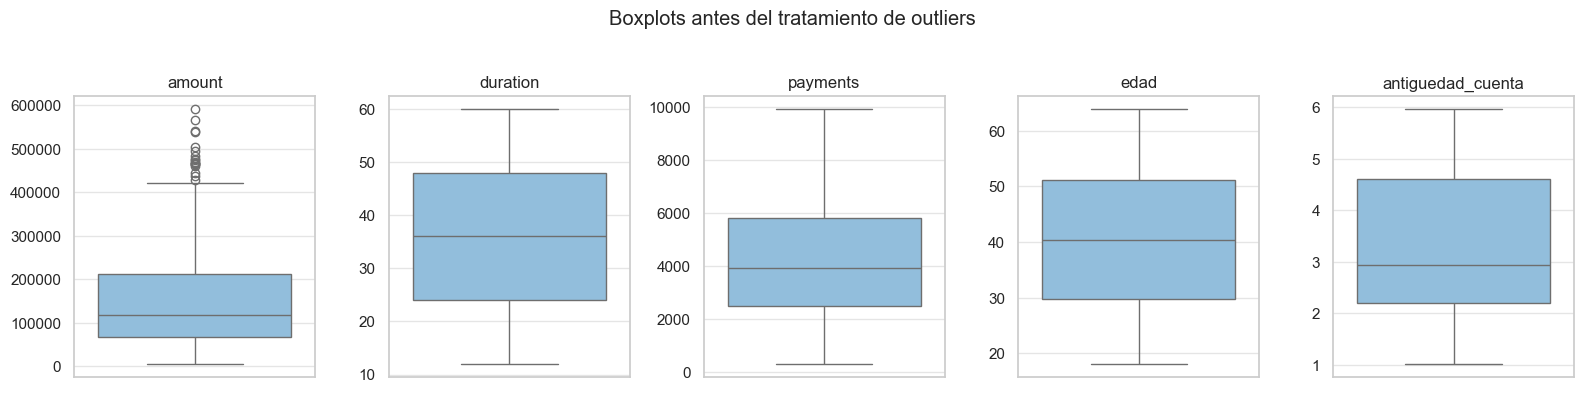

In [39]:
vars_cuant = ['amount', 'duration', 'payments', 'edad', 'antiguedad_cuenta']

fig, ax = plt.subplots(1, 5, figsize=(16, 3.8))
for a, v in zip(ax, vars_cuant):
    sns.boxplot(y=df_prep[v], ax=a, color='#85c1e9')
    a.set_title(v)
    a.set_ylabel('')
plt.suptitle('Boxplots antes del tratamiento de outliers', y=1.03)
plt.tight_layout()
plt.savefig(FIG / '02_boxplots_antes.png', dpi=130, bbox_inches='tight')
plt.show()

In [40]:
# --- Criterio 1: z-score ---------------------------------------------------
z = pd.DataFrame(np.abs(stats.zscore(df_prep[vars_cuant])), index=df_prep.index, columns=vars_cuant)
out_z = (z >= UMBRAL_Z)

# --- Criterio 2: IQR -------------------------------------------------------
Q1 = df_prep[vars_cuant].quantile(0.25)
Q3 = df_prep[vars_cuant].quantile(0.75)
IQR = Q3 - Q1
out_iqr = (df_prep[vars_cuant] < (Q1 - 1.5 * IQR)) | (df_prep[vars_cuant] > (Q3 + 1.5 * IQR))

por_variable = pd.DataFrame({'outliers_zscore': out_z.sum(), 'outliers_IQR': out_iqr.sum()})
print(por_variable)

# Efecto de cada criterio sobre las clases de la variable respuesta
def efecto(mascara, nombre):
    fil = mascara.any(axis=1)
    n0, n1 = int((df_prep.loc[fil, 'target'] == 0).sum()), int((df_prep.loc[fil, 'target'] == 1).sum())
    tot0, tot1 = int((df_prep['target'] == 0).sum()), int((df_prep['target'] == 1).sum())
    return {'criterio': nombre, 'filas_marcadas': int(fil.sum()),
            'de_clase_0_(mal_cliente)': n0, 'de_clase_1_(buen_cliente)': n1,
            '%_clase_0_perdida': round(n0 / tot0 * 100, 1), '%_clase_1_perdida': round(n1 / tot1 * 100, 1)}

comparacion = pd.DataFrame([efecto(out_z, 'z-score |z| >= 3'), efecto(out_iqr, 'IQR 1.5')])
comparacion

                   outliers_zscore  outliers_IQR
amount                           6            18
duration                         0             0
payments                         0             0
edad                             0             0
antiguedad_cuenta                0             0


,criterio,filas_marcadas,de_clase_0_(mal_cliente),de_clase_1_(buen_cliente),%_clase_0_perdida,%_clase_1_perdida
0,z-score |z| >= 3,6,1,5,1.3,0.8
1,IQR 1.5,18,6,12,7.9,2.0


### 5.1 Decisión sobre outliers

* Todos los atípicos están en **`amount`** (préstamos de monto muy alto). `duration` es discreta (12, 24, 36, 48, 60 meses), y `payments`, `edad` y `antiguedad_cuenta` no presentan atípicos.
* El criterio **IQR** marcaría 18 filas, incluyendo 6 clientes de la clase minoritaria (≈ 7,9 % de los malos clientes), que son justamente los que el modelo necesita aprender.
* El criterio **z-score** marca solo 6 filas (≈ 0,9 % de la población) y pierde únicamente 1 mal cliente. Es además el criterio usado en clase para eliminar atípicos.
* **Se aplica z-score (|z| ≥ 3) y se excluyen esas filas del análisis.** No son errores de captura (son préstamos legítimos de 60 meses y más de 495.000), pero su peso distorsiona la media, la desviación y el escalado z-score. Se guardan en `df_outliers` por trazabilidad.

In [41]:
filas_outlier = out_z.any(axis=1)
df_outliers = df_prep[filas_outlier].copy()
print('Filas atípicas excluidas (z >= 3):', len(df_outliers))
print(df_outliers[['client_id', 'amount', 'duration', 'payments', 'target']].sort_values('amount').to_string(index=False))

n_antes_out = len(df_prep)
df_prep_antes = df_prep.copy()          # copia para la comparación gráfica
df_prep = df_prep[~filas_outlier].copy()
print(f'\nFilas antes: {n_antes_out} | después: {len(df_prep)}')
print('Clase 0 / clase 1 después:', df_prep['target'].value_counts().sort_index().tolist())

Filas atípicas excluidas (z >= 3): 6
 client_id   amount  duration  payments  target
      8506 495180.0      60.0    8253.0       1
      3546 504000.0      60.0    8400.0       1
       981 538500.0      60.0    8975.0       1
      2823 541200.0      60.0    9020.0       0
     10997 566640.0      60.0    9444.0       1
      9340 590820.0      60.0    9847.0       1

Filas antes: 682 | después: 676
Clase 0 / clase 1 después: [75, 601]


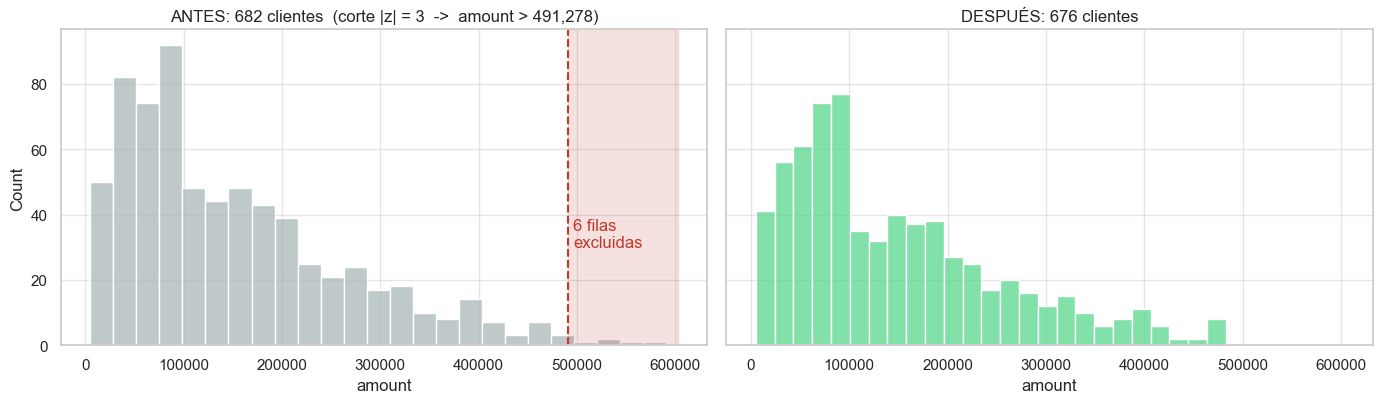

In [42]:
corte = df_prep_antes['amount'].mean() + UMBRAL_Z * df_prep_antes['amount'].std(ddof=0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True, sharey=True)
sns.histplot(df_prep_antes['amount'], bins=25, ax=ax[0], color='#aab7b8')
ax[0].axvline(corte, color='#c0392b', ls='--')
ax[0].set_title(f'ANTES: {n_antes_out} clientes  (corte |z| = 3  ->  amount > {corte:,.0f})')
ax[0].axvspan(corte, df_prep_antes['amount'].max() * 1.02, color='#c0392b', alpha=0.15)
ax[0].annotate(f'{len(df_outliers)} filas\nexcluidas', xy=(corte, 15), xytext=(corte + 5000, 30), color='#c0392b')

sns.histplot(df_prep['amount'], bins=25, ax=ax[1], color='#58d68d')
ax[1].set_title(f'DESPUÉS: {len(df_prep)} clientes')
plt.tight_layout()
plt.savefig(FIG / '03_amount_antes_despues.png', dpi=130, bbox_inches='tight')
plt.show()

## 6. One-hot encoding de variables cualitativas

Variables cualitativas que entran al modelo: `genero` (2 categorías), `frecuencia` (3) y `region` (8).
Se usa `pd.get_dummies` como en clase (Día 4 / `onehotencoding.ipynb`), con `dtype=int` para obtener columnas 0/1.
`sucursal_otro_distrito` ya es binaria (0/1) y no necesita codificación.

In [43]:
cols_cualitativas = ['genero', 'frecuencia', 'region']
dummies = pd.get_dummies(df_prep[cols_cualitativas], dtype=int)
print('Columnas dummy generadas:', dummies.shape[1])
print(dummies.columns.tolist())
print('\nCada fila suma 1 por variable original:',
      (dummies.filter(like='genero_').sum(axis=1) == 1).all() and
      (dummies.filter(like='frecuencia_').sum(axis=1) == 1).all() and
      (dummies.filter(like='region_').sum(axis=1) == 1).all())
dummies.head()

Columnas dummy generadas: 13
['genero_F', 'genero_M', 'frecuencia_mensual', 'frecuencia_por_transaccion', 'frecuencia_semanal', 'region_central_bohemia', 'region_east_bohemia', 'region_north_bohemia', 'region_north_moravia', 'region_prague', 'region_south_bohemia', 'region_south_moravia', 'region_west_bohemia']

Cada fila suma 1 por variable original: True


,genero_F,genero_M,frecuencia_mensual,frecuencia_por_transaccion,frecuencia_semanal,region_central_bohemia,region_east_bohemia,region_north_bohemia,region_north_moravia,region_prague,region_south_bohemia,region_south_moravia,region_west_bohemia
1,0,1,1,0,0,0,0,0,0,1,0,0,0
18,1,0,1,0,0,0,0,0,0,0,1,0,0
24,0,1,1,0,0,0,0,0,1,0,0,0,0
35,0,1,1,0,0,0,0,0,0,0,1,0,0
36,1,0,0,0,1,0,0,0,0,0,1,0,0


## 7. Reescalado z-score

Se estandarizan solo las **variables cuantitativas continuas** con `StandardScaler` (media 0, desviación estándar 1), como en el Día 4.
No se escalan las dummies, la llave ni la variable respuesta. Se hace **después** de eliminar los outliers para que la media y la desviación no estén distorsionadas por ellos.

In [44]:
scaler = StandardScaler()
X_z = pd.DataFrame(scaler.fit_transform(df_prep[vars_cuant]),
                   columns=[f'{v}_z' for v in vars_cuant], index=df_prep.index)

parametros = pd.DataFrame({'media_original': scaler.mean_, 'desv_est_original': scaler.scale_}, index=vars_cuant).round(3)
print('Parámetros usados para estandarizar (guardarlos permite reproducir/invertir la transformación):')
print(parametros)
print('\nVerificación tras el escalado:')
print(pd.DataFrame({'media': X_z.mean().round(6), 'desv_est': X_z.std(ddof=0).round(6)}))

Parámetros usados para estandarizar (guardarlos permite reproducir/invertir la transformación):
                   media_original  desv_est_original
amount                 147966.568         107660.119
duration                   36.284             16.993
payments                 4148.068           2176.527
edad                       40.467             12.654
antiguedad_cuenta           3.349              1.425

Verificación tras el escalado:
                     media  desv_est
amount_z              -0.0       1.0
duration_z             0.0       1.0
payments_z             0.0       1.0
edad_z                 0.0       1.0
antiguedad_cuenta_z    0.0       1.0


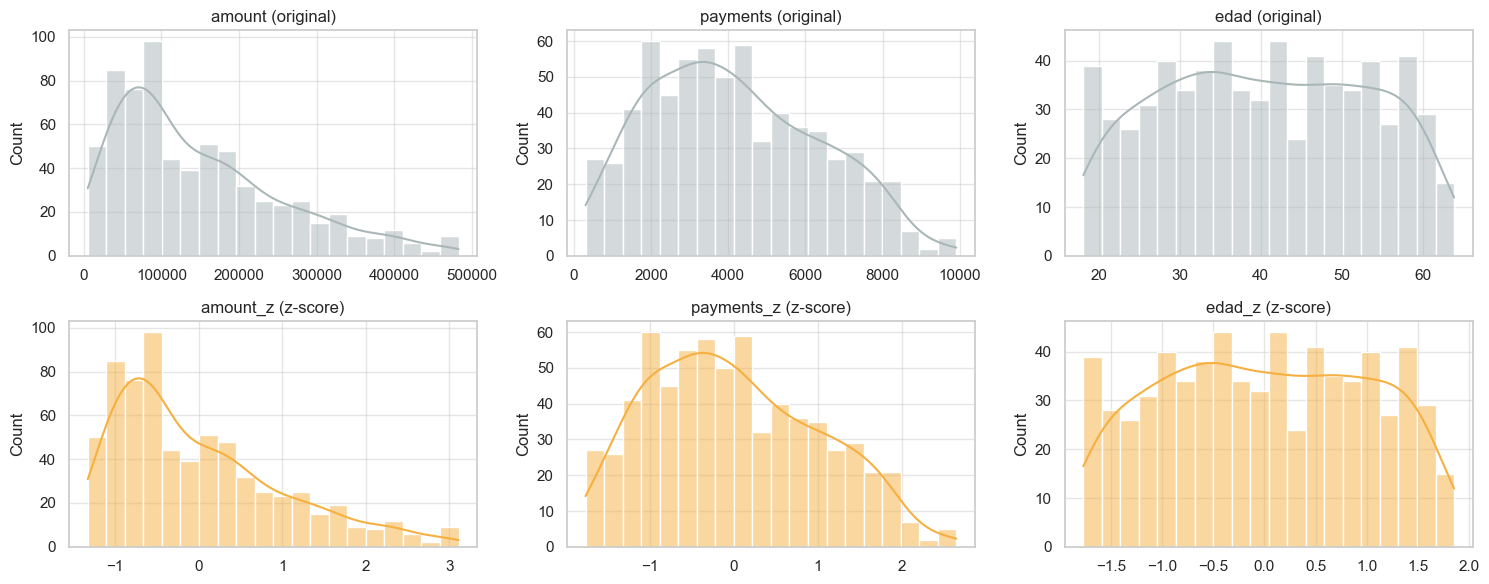

In [45]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for j, v in enumerate(['amount', 'payments', 'edad']):
    sns.histplot(df_prep[v], bins=20, kde=True, ax=ax[0, j], color='#aab7b8'); ax[0, j].set_title(f'{v} (original)')
    sns.histplot(X_z[f'{v}_z'], bins=20, kde=True, ax=ax[1, j], color='#f5b041'); ax[1, j].set_title(f'{v}_z (z-score)')
    ax[0, j].set_xlabel(''); ax[1, j].set_xlabel('')
plt.tight_layout()
plt.savefig(FIG / '04_zscore.png', dpi=130, bbox_inches='tight')
plt.show()

## 8. Ensamblado y validación de la tabla minable

Estructura final: `client_id` (llave, **no** es variable predictora) + variables cuantitativas estandarizadas + `sucursal_otro_distrito` + variables dummy + `target` (variable respuesta).

In [46]:
tabla_minable = pd.concat([df_prep[['client_id']],
                           X_z,
                           df_prep[['sucursal_otro_distrito']],
                           dummies,
                           df_prep[['target']]], axis=1)

print('Dimensión final:', tabla_minable.shape)
tabla_minable.head()

Dimensión final: (676, 21)


,client_id,amount_z,duration_z,payments_z,edad_z,antiguedad_cuenta_z,sucursal_otro_distrito,genero_F,genero_M,frecuencia_mensual,...,frecuencia_semanal,region_central_bohemia,region_east_bohemia,region_north_bohemia,region_north_moravia,region_prague,region_south_bohemia,region_south_moravia,region_west_bohemia,target
1,2,-0.622464,-0.722876,-0.356103,1.061535,1.748134,0,0,1,1,...,0,0,0,0,0,1,0,0,0,1
18,25,-1.093168,-1.429037,-0.746634,1.519892,0.267276,0,1,0,1,...,0,0,0,0,0,0,1,0,0,0
24,31,-1.093168,-1.429037,-0.746634,-0.281926,-0.645101,0,0,1,1,...,0,0,0,0,1,0,0,0,0,1
35,45,1.583812,1.395610,0.532928,0.460929,-1.389039,0,0,1,1,...,0,0,0,0,0,0,1,0,0,0
36,46,-0.345816,0.689448,-0.845874,1.456670,-1.367984,0,1,0,0,...,1,0,0,0,0,0,1,0,0,1


In [50]:
tabla_minable.to_csv('tabla_minable_berka.csv', index=False)

# Comprobación de lectura
chk = pd.read_csv('tabla_minable_berka.csv')
print('CSV guardado y releído:', chk.shape, '| igual a la tabla en memoria:', chk.shape == tabla_minable.shape)

CSV guardado y releído: (676, 21) | igual a la tabla en memoria: True


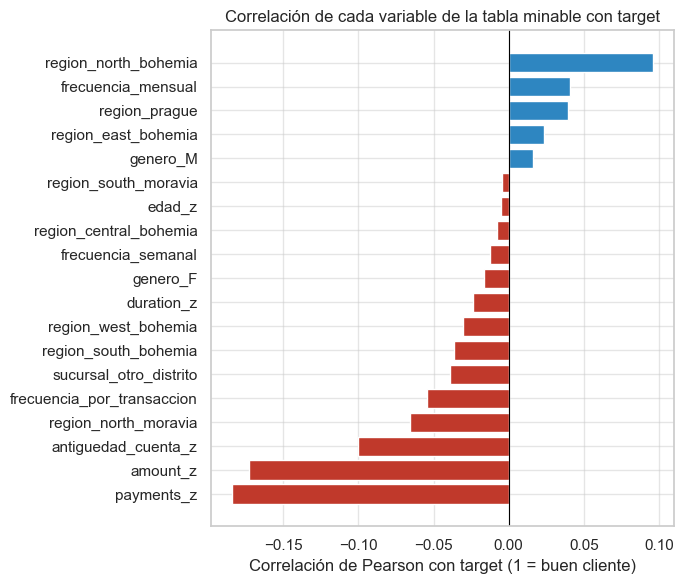

payments_z                   -0.184
amount_z                     -0.172
antiguedad_cuenta_z          -0.100
region_north_bohemia          0.096
region_north_moravia         -0.066
frecuencia_por_transaccion   -0.054
Name: target, dtype: float64

In [48]:
# Vista rápida: relación de cada variable preparada con la respuesta (correlación con target)
corr_target = (tabla_minable.drop(columns='client_id').corr()['target']
               .drop('target').sort_values())
plt.figure(figsize=(7, 6))
plt.barh(corr_target.index, corr_target.values,
         color=['#c0392b' if v < 0 else '#2e86c1' for v in corr_target.values])
plt.axvline(0, color='black', lw=0.8)
plt.title('Correlación de cada variable de la tabla minable con target')
plt.xlabel('Correlación de Pearson con target (1 = buen cliente)')
plt.tight_layout()
plt.savefig(FIG / '05_correlacion_target.png', dpi=130, bbox_inches='tight')
plt.show()
corr_target.round(3).sort_values(key=abs, ascending=False).head(6)

In [49]:
# Verificación de redundancia: ¿payments = amount / duration?
tabla_origen_chk = df_berka[tiene_prestamo]
dif = (tabla_origen_chk['payments'] - tabla_origen_chk['amount'] / tabla_origen_chk['duration']).abs().max()
print('Diferencia máxima |payments - amount/duration| =', round(dif, 6))
print('Correlación de Pearson amount vs payments:', round(tabla_origen_chk[['amount', 'payments']].corr().iloc[0, 1], 3))

Diferencia máxima |payments - amount/duration| = 0.0
Correlación de Pearson amount vs payments: 0.689
